In [13]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

DATA_DIR = REPO_ROOT / "data"
SAMPLE_FILE = DATA_DIR / "final_sample_zsun0.fits"
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 12,
    "axes.labelsize": 13,
})

In [14]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(0.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)
    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.75))
    h2   = numpyro.deterministic("h2", h1 + d_h2)
    z0     = numpyro.sample("z0",     dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))
    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset
    Q = numpyro.deterministic("Q", 0.0)
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
                  dist.Normal(model_y, data["mg_fe_err"])]
    numpyro.sample("obs", dist.Mixture(mix, components), obs=data["mg_fe"])


In [15]:
# =============================================================================
# Sech2 fits in radial bins only (all azimuths combined), for h_eff later
# =============================================================================
from tqdm import tqdm

R_FLARE_LO, R_FLARE_HI, R_WIDTH = 3.5, 15.5, 0.5       # bin width [kpc]
FLARE_EDGES = np.arange(R_FLARE_LO, R_FLARE_HI + 1e-6, R_WIDTH)
n_flare = len(FLARE_EDGES) - 1

WEDGE_ONLY  = False      # True = only stars inside the 11-segment wedge
FLARE_PATH  = DATA_DIR / f"sech2_fits_flare_{R_WIDTH:g}kpc.pkl"
FORCE_RERUN = False

if FLARE_PATH.exists() and not FORCE_RERUN:
    with open(FLARE_PATH, "rb") as f:
        per_R_flare = pickle.load(f)["per_R_flare"]
    print(f"loaded {FLARE_PATH.name}: {len(per_R_flare)} of {n_flare} radial bins fit")
else:
    m_base = (np.isfinite(R_star) & np.isfinite(Z_star) & np.isfinite(mgfe_star)
              & np.isfinite(err_star) & (err_star > 0))
    if WEDGE_ONLY:
        m_base &= (phi_star >= seg_bounds[0]) & (phi_star < seg_bounds[-1])

    per_R_flare = {}
    key = jr.PRNGKey(0)
    for i in tqdm(range(n_flare), desc="fitting radial bins"):
        Rlo, Rhi = float(FLARE_EDGES[i]), float(FLARE_EDGES[i + 1])
        m = m_base & (R_star >= Rlo) & (R_star < Rhi)
        n = int(m.sum())
        if n < minN_seg_total:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipped, only {n} stars")
            continue

        zc, mean, err, cnt = bin_one(Z_star[m], mgfe_star[m], err_star[m])
        good = (np.isfinite(mean) & np.isfinite(err) & (cnt >= min_bin_count)
                & (zc >= z_fit_min) & (zc <= z_fit_max))
        if good.sum() < min_bins_for_fit:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipped, only {int(good.sum())} good z bins")
            continue

        try:
            key, sub = jr.split(key)
            samples = fit_sech2(zc[good].astype(float), mean[good].astype(float),
                                err[good].astype(float), sub).get_samples()
            per_R_flare[i] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n,
                              "z_binc": zc[good], "mean": mean[good], "err": err[good],
                              "samples": {k: np.asarray(v) for k, v in samples.items()}}
        except Exception as e:
            print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

    with open(FLARE_PATH, "wb") as f:
        pickle.dump({"per_R_flare": per_R_flare, "flare_edges": FLARE_EDGES}, f)
    print(f"fits complete: {len(per_R_flare)} of {n_flare} bins, saved {FLARE_PATH}")

loaded sech2_fits_flare_0.5kpc.pkl: 24 of 24 radial bins fit


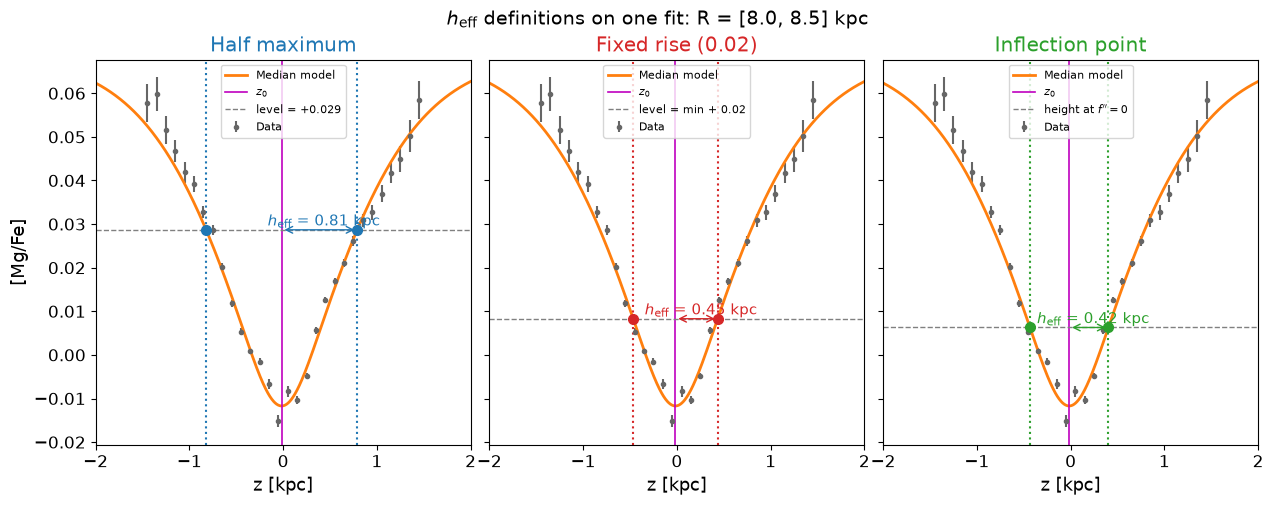

{'half': 0.806, 'fixed': 0.45, 'infl': 0.419}


In [16]:
from scipy.optimize import brentq
import jax
import jax.numpy as jnp

R_TARGET = 8.25     # kpc, center of the radial bin to show (Sun's bin)
DROP     = 0.02    # fixed-rise definition: level = minimum + DROP in [Mg/Fe]

# ---- pick the bin and its median-parameter model ----
i_sel = min(per_R_flare,
            key=lambda i: abs(0.5 * (per_R_flare[i]["Rlo"] + per_R_flare[i]["Rhi"]) - R_TARGET))
cell = per_R_flare[i_sel]
med = {k: float(np.median(v)) for k, v in cell["samples"].items()}
A1, A2, z0, off = med["A1"], med["A2"], med["z0"], med["offset"]
h1, h2 = med["h1"], med["h1"] + med["d_h2"]

def f(z):                      
    return mixture_of_sech2(z, A1, A2, h1, h2, z0)

d2 = jax.grad(jax.grad(lambda z: mixture_of_sech2(z, A1, A2, h1, h2, z0)))   # f''(z)

f_min = A1 + A2               
levels = {"half": 0.5 * f_min, "fixed": f_min + DROP}

def crossing(level):
    try:
        return brentq(lambda z: float(f(z)) - level, z0 + 1e-9, z0 + 8 * max(h1, h2)) - z0
    except ValueError:
        return np.nan

def inflection():
    for lo, hi in ((z0 + 0.658 * min(h1, h2), z0 + 0.658 * max(h1, h2)),
                   (z0 + 1e-3, z0 + 8 * max(h1, h2))):
        try:
            return brentq(lambda z: float(d2(z)), lo, hi) - z0
        except ValueError:
            continue
    return np.nan

h_eff = {"half": crossing(levels["half"]),
         "fixed": crossing(levels["fixed"]),
         "infl": inflection()}

# ---- figure ----
z_grid = np.linspace(-2, 2, 1000)
y_model = np.asarray(f(z_grid)) + off

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.05))

panels = [
    ("half",  "Half maximum",           "C0", f"level = {levels['half'] + off:+.3f}"),
    ("fixed", f"Fixed rise ({DROP:g})", "C3", f"level = min + {DROP:g}"),
    ("infl",  "Inflection point",       "C2", r"$f''(z)=0$"),
]

for ax, (key, title, color, note) in zip(axes, panels):
    h = h_eff[key]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="0.4", marker=".", linestyle="", label="Data")
    ax.plot(z_grid, y_model, color="C1", lw=2, label="Median model")
    ax.axvline(z0, color="m", lw=1.2, label=r"$z_0$")

    if key in ("half", "fixed"):
        y_pts = levels[key] + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=note)
    else:
        y_pts = float(f(z0 + h)) + off
        ax.axhline(y_pts, color="gray", ls="--", lw=1, label=r"height at $f''=0$")

    for sgn in (-1, 1):
        ax.axvline(z0 + sgn * h, color=color, ls=":", lw=1.5)
    ax.plot([z0 - h, z0 + h], [y_pts, y_pts], "o", color=color, ms=7, zorder=5)
    ax.annotate("", xy=(z0 + h, y_pts), xytext=(z0, y_pts),
                arrowprops=dict(arrowstyle="<->", color=color))
    ax.text(z0 + h / 2, y_pts, f"  $h_\\mathrm{{eff}}$ = {h:.2f} kpc", color=color,
            va="bottom", ha="center", fontsize=11)

    ax.set_title(title, color=color)
    ax.set_xlabel("z [kpc]")
    ax.set_xlim(-2, 2)
    ax.legend(loc="upper center", fontsize=8)

axes[0].set_ylabel("[Mg/Fe]")
fig.suptitle(f"$h_\\mathrm{{eff}}$ definitions on one fit: R = [{cell['Rlo']:.1f}, {cell['Rhi']:.1f}] kpc",
             fontsize=14)
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "h_eff_methods_single_fit.pdf", bbox_inches="tight")
plt.show()

print({k: round(v, 3) for k, v in h_eff.items()})

f'' check: jax.grad = 0.10445, analytic = 0.10445
     R [kpc]        N      h_eff [kpc]
  3.5-4.0        821     0.411 +/- 0.114
  4.0-4.5      1,119     0.529 +/- 0.150
  4.5-5.0      1,695     0.134 +/- 0.043
  5.0-5.5      2,248     0.372 +/- 0.082
  5.5-6.0      3,459     0.158 +/- 0.022
  6.0-6.5      5,961     0.111 +/- 0.020
  6.5-7.0      8,796     0.118 +/- 0.016
  7.0-7.5     15,559     0.157 +/- 0.030
  7.5-8.0     25,596     0.381 +/- 0.057
  8.0-8.5     49,898     0.426 +/- 0.035
  8.5-9.0     46,142     0.166 +/- 0.026
  9.0-9.5     41,055     0.224 +/- 0.024
  9.5-10.0    32,065     0.589 +/- 0.038
 10.0-10.5    23,725     0.591 +/- 0.033
 10.5-11.0    18,740     0.677 +/- 0.060
 11.0-11.5    15,192     0.727 +/- 0.067
 11.5-12.0    12,190     0.576 +/- 0.053
 12.0-12.5     9,495     0.564 +/- 0.049
 12.5-13.0     7,129     0.513 +/- 0.068
 13.0-13.5     4,844     0.641 +/- 0.089
 13.5-14.0     3,433     0.457 +/- 0.077
 14.0-14.5     2,181     0.584 +/- 0.118
 14.5-15.

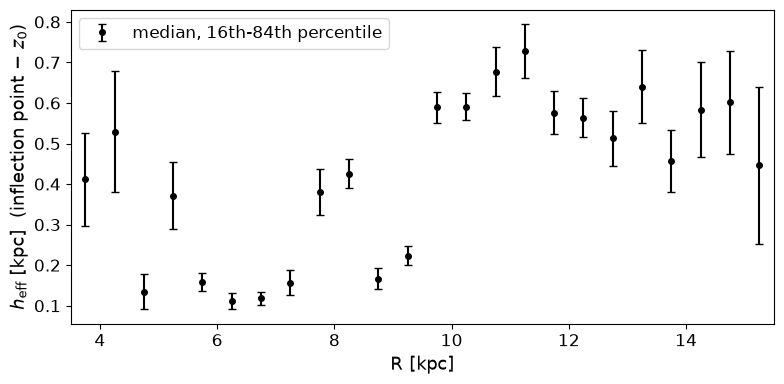

In [17]:
# =============================================================================
# h_eff from the inflection point of the dip: solve d^2 f / dz^2 = 0 for z > z0
# =============================================================================
import matplotlib.pyplot as plt

K_INFL = np.arctanh(1 / np.sqrt(3))      # 0.658: inflection of a single sech^2(u)

# second derivative of the actual model with respect to z, vectorized over posterior samples
d2_jax = jax.grad(jax.grad(mixture_of_sech2, argnums=0), argnums=0)
d2_vec = jax.jit(jax.vmap(d2_jax))       # arguments: z, A1, A2, h1, h2, z0 (all arrays)

def inflection_height(s, n_iter=40):
    """h_eff = z_root - z0 for every posterior sample (bisection on f'' from jax.grad)."""
    A1, A2, h1, h2, z0 = (jnp.asarray(np.asarray(s[k])) for k in ("A1", "A2", "h1", "h2", "z0"))
    lo = z0 + K_INFL * h1      # f'' > 0 here
    hi = z0 + K_INFL * h2      # f'' < 0 here (h2 > h1)
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        pos = d2_vec(mid, A1, A2, h1, h2, z0) > 0
        lo = jnp.where(pos, mid, lo)
        hi = jnp.where(pos, hi, mid)
    return np.asarray(0.5 * (lo + hi) - z0)

# --- sanity check: jax second derivative vs the closed form for sech^2 ---
def d2f_analytic(z, A1, A2, h1, h2, z0):
    out = 0.0
    for A, h in ((A1, h1), (A2, h2)):
        t = np.tanh((z - z0) / h)
        out = out + A / h**2 * (1 - t**2) * (6 * t**2 - 2)
    return out

i0 = sorted(per_R_flare)[0]
s0 = {k: float(v[0]) for k, v in per_R_flare[i0]["samples"].items()}
zt = s0["z0"] + 0.3
a = float(d2_jax(zt, s0["A1"], s0["A2"], s0["h1"], s0["h2"], s0["z0"]))
b = float(d2f_analytic(zt, s0["A1"], s0["A2"], s0["h1"], s0["h2"], s0["z0"]))
print(f"f'' check: jax.grad = {a:.5f}, analytic = {b:.5f}")
assert np.isclose(a, b, rtol=1e-3), "jax and analytic second derivatives disagree"

# --- h_eff in every radial bin, using all posterior samples ---
R_cent = 0.5 * (FLARE_EDGES[:-1] + FLARE_EDGES[1:])
h_eff_med = np.full(n_flare, np.nan)
h_eff_err = np.full(n_flare, np.nan)
h_eff_samples = {}

for i, cell in per_R_flare.items():
    h = inflection_height(cell["samples"])
    h_eff_samples[i] = h
    p16, p50, p84 = np.percentile(h, [16, 50, 84])
    h_eff_med[i], h_eff_err[i] = p50, 0.5 * (p84 - p16)

print(f"{'R [kpc]':>12s} {'N':>8s} {'h_eff [kpc]':>16s}")
for i in sorted(per_R_flare):
    c = per_R_flare[i]
    print(f"{c['Rlo']:5.1f}-{c['Rhi']:<5.1f} {c['n_stars']:>8,d} "
          f"{h_eff_med[i]:>9.3f} +/- {h_eff_err[i]:.3f}")

# --- plot ---
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_cent, h_eff_med, yerr=h_eff_err, fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]  (inflection point $-\ z_0$)")
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_HEFF = FIG_DIR / "h_eff_inflection"
fig.savefig(OUT_STEM_HEFF.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_HEFF.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()

R=15.0-15.5: fixed-rise root exists for only 1337/2000 samples (dip shallower than 0.02 in the rest)
    R [kpc]       inflection         half-max       fixed rise
  3.5-4.0       0.411+/-0.114     0.605+/-0.155     0.384+/-0.079
  4.0-4.5       0.529+/-0.150     0.773+/-0.211     0.455+/-0.090
  4.5-5.0       0.134+/-0.043     0.568+/-0.065     0.181+/-0.043
  5.0-5.5       0.372+/-0.082     0.620+/-0.075     0.321+/-0.035
  5.5-6.0       0.158+/-0.022     0.532+/-0.054     0.188+/-0.018
  6.0-6.5       0.111+/-0.020     0.490+/-0.046     0.149+/-0.020
  6.5-7.0       0.118+/-0.016     0.614+/-0.027     0.196+/-0.021
  7.0-7.5       0.157+/-0.030     0.664+/-0.027     0.265+/-0.023
  7.5-8.0       0.381+/-0.057     0.773+/-0.039     0.402+/-0.019
  8.0-8.5       0.426+/-0.035     0.791+/-0.041     0.445+/-0.013
  8.5-9.0       0.166+/-0.026     0.685+/-0.018     0.312+/-0.014
  9.0-9.5       0.224+/-0.024     0.708+/-0.019     0.358+/-0.012
  9.5-10.0      0.589+/-0.038     0.849+/-0.

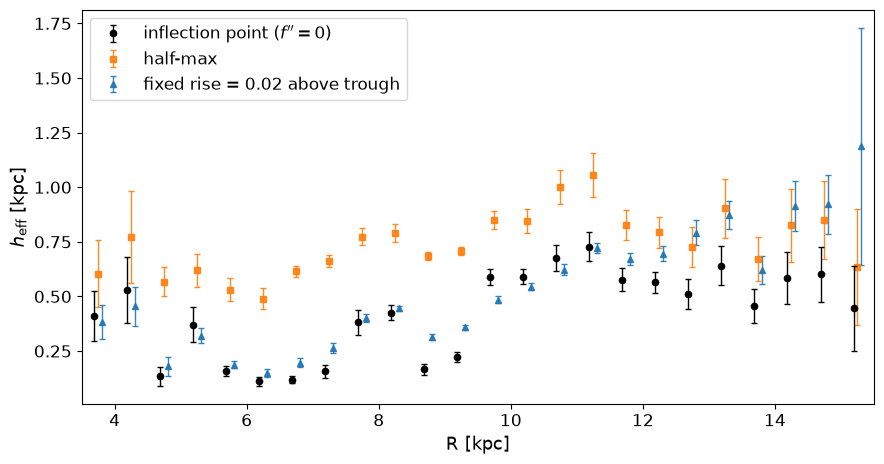

In [18]:
# =============================================================================
# Three h_eff definitions, same posterior samples: inflection, half-max, fixed rise
# =============================================================================
import matplotlib.pyplot as plt

DROP = 0.02          # fixed-rise definition: rise above the trough [dex]

def crossing_height(s, kind, drop=DROP, n_iter=50):
    """z - z0 where the dip profile (no offset) reaches a target level, for every posterior sample.
    kind = "half":  target = half of the dip depth, 0.5 * (A1 + A2)
    kind = "fixed": target = trough + drop, i.e. the profile has risen by `drop` above its minimum
    Samples whose profile never reaches the target return NaN."""
    A1, A2, h1, h2, z0 = (jnp.asarray(np.asarray(s[k])) for k in ("A1", "A2", "h1", "h2", "z0"))
    trough = A1 + A2                                   #
    target = 0.5 * trough if kind == "half" else trough + drop

    lo = z0                                            
    hi = z0 + 8 * jnp.maximum(h1, h2)                  
    reaches = mixture_of_sech2(hi, A1, A2, h1, h2, z0) > target
    for _ in range(n_iter):                            
        mid = 0.5 * (lo + hi)
        below = mixture_of_sech2(mid, A1, A2, h1, h2, z0) < target
        lo = jnp.where(below, mid, lo)
        hi = jnp.where(below, hi, mid)
    h = np.asarray(0.5 * (lo + hi) - z0)
    return np.where(np.asarray(reaches), h, np.nan)

def summarize(h):
    h = h[np.isfinite(h)]
    if len(h) == 0:
        return np.nan, np.nan, 0
    p16, p50, p84 = np.percentile(h, [16, 50, 84])
    return p50, 0.5 * (p84 - p16), len(h)

h_half_med  = np.full(n_flare, np.nan); h_half_err  = np.full(n_flare, np.nan)
h_fixed_med = np.full(n_flare, np.nan); h_fixed_err = np.full(n_flare, np.nan)
h_half_samples, h_fixed_samples = {}, {}

for i, cell in per_R_flare.items():
    s = cell["samples"]
    h_half_samples[i]  = crossing_height(s, "half")
    h_fixed_samples[i] = crossing_height(s, "fixed")
    h_half_med[i],  h_half_err[i],  _ = summarize(h_half_samples[i])
    h_fixed_med[i], h_fixed_err[i], n_ok = summarize(h_fixed_samples[i])
    if n_ok < 0.9 * len(s["z0"]):
        print(f"R={cell['Rlo']:.1f}-{cell['Rhi']:.1f}: fixed-rise root exists for only "
              f"{n_ok}/{len(s['z0'])} samples (dip shallower than {DROP} in the rest)")

print(f"{'R [kpc]':>11s} {'inflection':>16s} {'half-max':>16s} {'fixed rise':>16s}")
for i in sorted(per_R_flare):
    c = per_R_flare[i]
    print(f"{c['Rlo']:5.1f}-{c['Rhi']:<5.1f} "
          f"{h_eff_med[i]:>9.3f}+/-{h_eff_err[i]:.3f} "
          f"{h_half_med[i]:>9.3f}+/-{h_half_err[i]:.3f} "
          f"{h_fixed_med[i]:>9.3f}+/-{h_fixed_err[i]:.3f}")

dx = 0.06
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(R_cent - dx, h_eff_med, yerr=h_eff_err, fmt="o", lw=1, color="k",
            ms=4.5, capsize=2.5, label="inflection point ($f''=0$)", zorder=3)
ax.errorbar(R_cent, h_half_med, yerr=h_half_err, fmt="s", lw=1, color="tab:orange",
            ms=4.5, capsize=2.5, alpha=0.9, label="half-max", zorder=2)
ax.errorbar(R_cent + dx, h_fixed_med, yerr=h_fixed_err, fmt="^", lw=1, color="tab:blue",
            ms=5, capsize=2.5, alpha=0.9, label=f"fixed rise = {DROP} above trough", zorder=2)
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(FLARE_EDGES[0], FLARE_EDGES[-1])
ax.legend(loc="upper left")
plt.tight_layout()
OUT_STEM_CMP = FIG_DIR / "h_eff_three_definitions"
fig.savefig(OUT_STEM_CMP.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(OUT_STEM_CMP.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()